## **$Cayden Sim-p2510893-DAAA/FT/1B/01$** 
---
### **CA1 Part B**:



### **Background Overview for Part B (Regression Task)**

- This regression task focuses on predicting housing prices based on several key property features.  
- The dataset contains attributes such as the number of bedrooms, number of toilets, and the overall floor area of the house.  
- Each of these features plays an important role in determining the market price of a property, and the goal of this task is to use machine learning techniques to build a model that accurately estimates house prices from these inputs.



## **My Planned Workflow:**
- The workflow includes data exploration, preprocessing, model building, evaluation, and improvement using *numpy*, *pandas* and *scikit-learn* regression models.
- Visuals and Graphs will be plotted with the help of *Matplotlib* and S*eaborn*.



---
## **Step 1**: Importing the Necessary Libraries & Their Models


In [1]:
#importing libraries and models
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
import seaborn as sns
import matplotlib.pyplot as plt

- Essential libraries like pandas and numpy are imported for data handling and analysis.
- Matplotlib and Seaborn are also imported for the display of visuals and graphs.

- Machine learning tools from scikit-learn such as, *train_test_split, cross_val_score, KFold, GridSearchCV, LabelEncoder, StandardScaler classification_report, accuracy_score,  precision_score, recall_score, confusion_matrix, DummyClassifier* are also imported to build, train, and evaluate the regression models.

## **Step 2:** Loading Datasets Using pandas' ***`'.read_csv'`*** method


In [2]:
df = pd.read_csv("C:/Users/nedya/OneDrive/Desktop/AIML/CA1/CA1-Dataset/housing_price_data.csv")
df

,House ID,City,House Area (sqm),No. of Bedrooms,No. of Toilets,Stories,Renovation Status,Price ($)
0,0,Chicago,742.0,4,2,3,furnished,1330000
1,1,Denver,896.0,4,4,4,furnished,1225000
2,2,Chicago,996.0,3,2,2,semi-furnished,1225000
3,3,Seattle,750.0,4,2,2,furnished,1221500
4,4,New York,742.0,4,1,2,furnished,1141000
...,...,...,...,...,...,...,...,...
540,540,Seattle,300.0,2,1,1,unfurnished,182000
541,541,New York,240.0,3,1,1,semi-furnished,176715
542,542,Boston,362.0,2,1,1,unfurnished,175000
543,543,Seattle,291.0,3,1,1,furnished,175000


- Used pandas' built in function called ***`'pd.read_csv`***' to load the CSV file containing the datasets for this assignment.

---
## **Step 3** : Exploratory Data Analysis **(EDA)**

- Identifying major outliers that can affect the output of the machine.

- Using a few diagrams to visualise the spread of the data per column to identify any major outliers.

- Identifying missing values in columns and adding them to find the total value of the missing values.

### **Columns:**
   - **Numerical Columns**: House Area (sqm), City, No. of Bedrooms, No. of Toilets, Stories, Renovation Status

   - **Categorical Columns**: House ID

- For more information on the different column datas, refer to the display below.

In [3]:
print("Shape of the dataframe: \n", df.shape)
print("Info on dataframe: ", df.info())


Shape of the dataframe: 
 (545, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   House ID           545 non-null    int64  
 1   City               545 non-null    object 
 2   House Area (sqm)   545 non-null    float64
 3   No. of Bedrooms    545 non-null    int64  
 4   No. of Toilets     545 non-null    int64  
 5   Stories            545 non-null    int64  
 6   Renovation Status  545 non-null    object 
 7   Price ($)          545 non-null    int64  
dtypes: float64(1), int64(5), object(2)
memory usage: 34.2+ KB
Info on dataframe:  None


- From the ***`.shape`*** attribute and ***`info()`*** method outputs, it is displayed that the dataset contains **545 rows and 8 columns**, with a mix of mostly integer and float value

- All columns are complete and do not have any missing values as shown by the non-null count.



In [4]:
print("Here is the dataframe description: \n", df.describe())

Here is the dataframe description: 
         House ID  House Area (sqm)  No. of Bedrooms  No. of Toilets  \
count  545.00000        545.000000       545.000000      545.000000   
mean   272.00000        515.054128         2.965138        1.286239   
std    157.47222        217.014102         0.738064        0.502470   
min      0.00000        165.000000         1.000000        1.000000   
25%    136.00000        360.000000         2.000000        1.000000   
50%    272.00000        460.000000         3.000000        1.000000   
75%    408.00000        636.000000         3.000000        2.000000   
max    544.00000       1620.000000         6.000000        4.000000   

          Stories     Price ($)  
count  545.000000  5.450000e+02  
mean     1.805505  4.766729e+05  
std      0.867492  1.870440e+05  
min      1.000000  1.750000e+05  
25%      1.000000  3.430000e+05  
50%      2.000000  4.340000e+05  
75%      2.000000  5.740000e+05  
max      4.000000  1.330000e+06  


The ***`.describe()`*** summary provides an overview of key statistical properties such as the mean, standard deviation, and minimum/maximum values for each numerical feature. 

### **Additional Visuals:**
- Additional visuals are added via ***`Matplotlib`*** and ***`Seaborn`*** to allow better understanding and visualization of the dataset.

### **Histogram:**

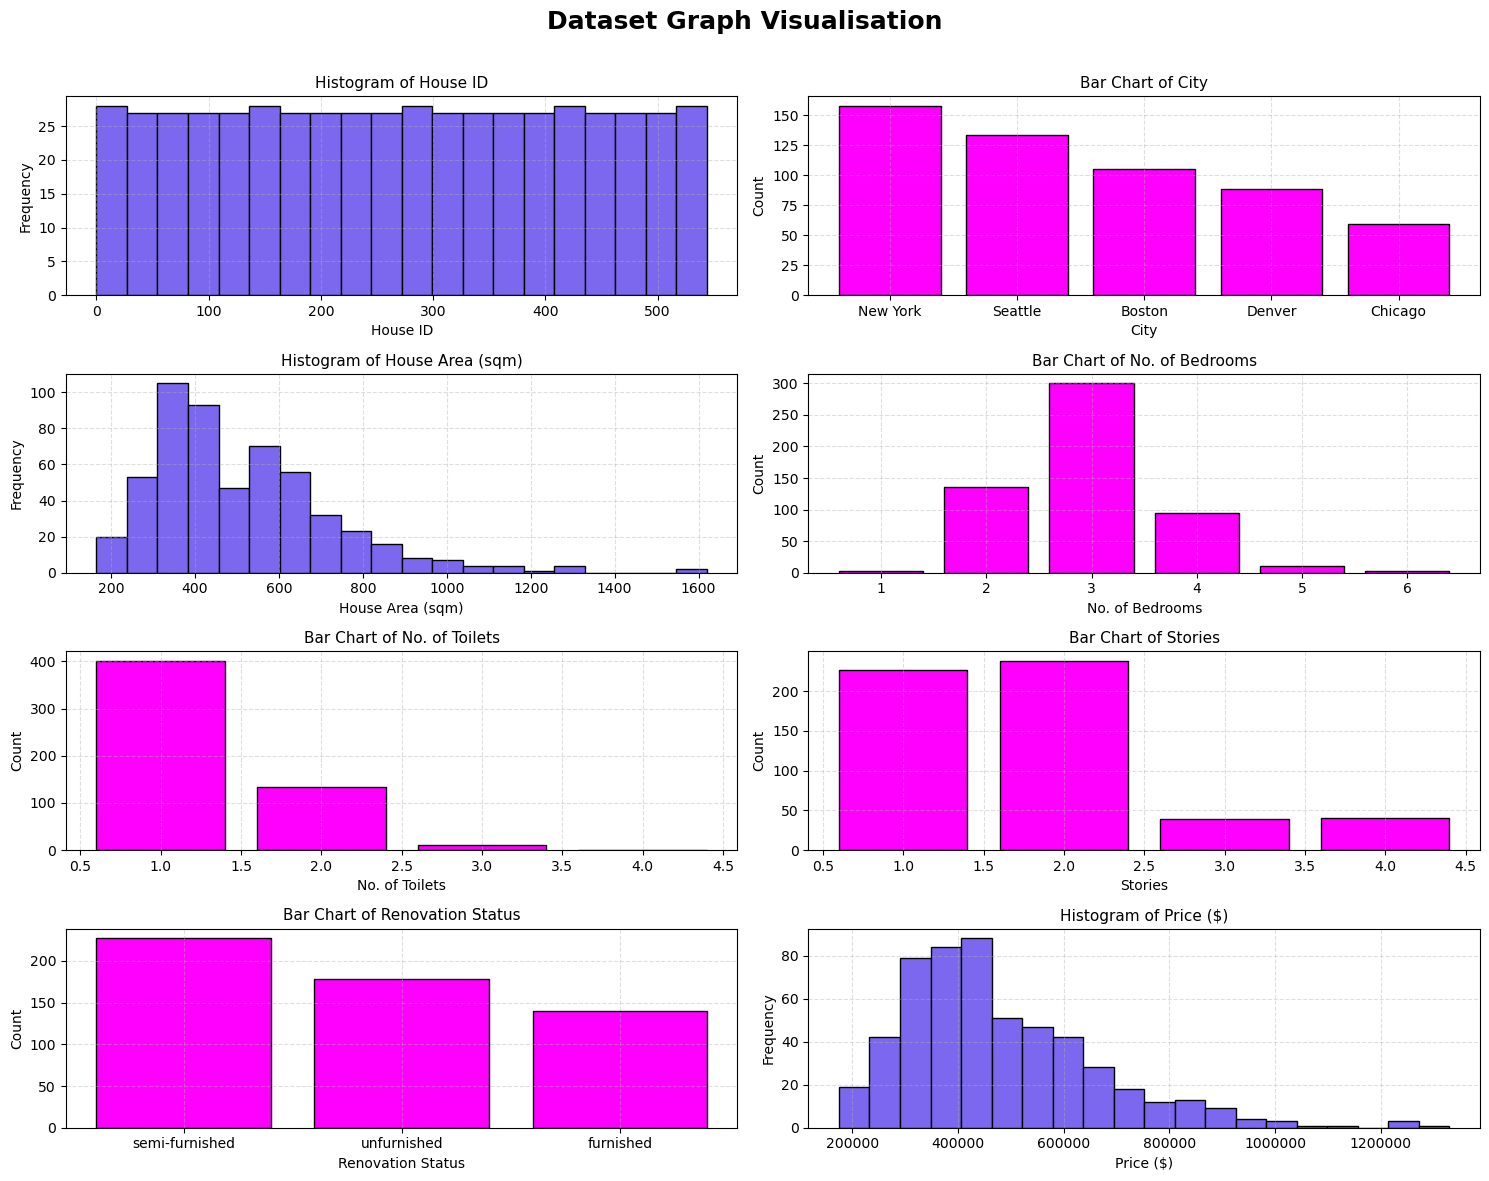

In [5]:
housing_cols = ['House ID', 'City', 'House Area (sqm)', 'No. of Bedrooms',
                 'No. of Toilets', 'Stories', 'Renovation Status', 'Price ($)']

plt.figure(figsize=(15, 12))
plt.suptitle("Dataset Graph Visualisation", fontsize=18, fontweight='bold')

# If a column has many unique numeric values → histogram to show distribution shape
# If a column has few categories (like city names or renovation status) → bar chart to show counts
for i, col in enumerate(housing_cols, 1):
    plt.subplot(4, 2, i)      

    if df[col].nunique() > 10:
        
        # Histogram used for continuous or high-unique-value numeric columns
        # Helps show data spread, skew, common ranges, and potential outliers
        plt.hist(df[col], bins=20, edgecolor='black', color='mediumslateblue')
        plt.ylabel("Frequency")
        plt.title(f"Histogram of {col}", fontsize=11)
        plt.grid(True, linestyle='--', alpha=0.4)
    else:
        
        # Bar chart used for categorical or low-unique-value columns
        # Helps show which categories appear most (e.g., cities or renovation types)
        counts = df[col].value_counts()
        plt.bar(counts.index, counts.values, color='magenta', edgecolor='black')
        plt.ylabel("Count")
        plt.title(f"Bar Chart of {col}", fontsize=11)
        plt.grid(True, linestyle='--', alpha=0.4)

    plt.xlabel(col)

# Adjust spacing so title and plots don't overlap
plt.tight_layout(rect=[0, 0, 1, 0.97])  

# Removes scientific notation for easier analysis
plt.ticklabel_format(style='plain', axis='x')
# display the graph
plt.show()

## **Explanation:**

### **Overview:**
- These graphs visualizes all major features in the housing dataset using a combination of histograms for continuous numerical variables (House ID, House Area and Price) and bar charts for categorical variables (City, No. of Bedrooms, No. of toilets, Stories and Renvation Status).
- Despite No. of Bedrooms and toilets are numbers, they are considered categorical as there is an order/range to the number of bedrooms and toilets (From 1 t 6 for bedrooms and 1 to 4 for toilets). 
    - This shows that despite being numbers, they are not continuous hence are not classed as numerical variables. Same goes for Stories and Renovation Status.
- This helps us quickly understand how each feature is distributed.


### **Code Structure:**
- `'housing_cols'` holds a list of the column headers that contain the data we want to visualise/display.
- `'enumerate(housing_cols, 1)'` adds a counter to an iterable:
    - where `'housing_cols'` is the list the code is iterating over
    - 1 tells ***`'enumerate'`*** function to start counting from 1 instead of the default 0.
- `'for i, col in enumerate(housing_cols, 1)'` loops through the 8 column headers.
-  `if df[col].nunique() > 10:` 
        
        plt.hist(df[col], bins=20, edgecolor='black', color='mediumslateblue')
        plt.ylabel("Frequency")
        plt.title(f"Histogram of {col}", fontsize=11)
    tells the code that if a column has more than 10 different unique values, then plot a histogram. This is to check whether the column is a continuous numerical variable or not
- `else:`
    
        `counts = df[col].value_counts()` (***`'.value_counts()'`*** calculates how many houses fall in each category)
    
        `plt.bar(counts.index, counts.values, color='hotpink', edgecolor='black')`
    tells the code that if the column does not have 10 different unique values, then run this code where a bar graph is plotted instead of a histogram since the columns are categorical variables.

- `'plt.tight_layout(rect=[0, 0, 1, 0.97])'` ensures that the subplots do not overlap.
  
- `'plt.ticklabel_format(style='plain', axis='x')'` fixes long values on the x-axis so that they appear in their normal values and not in scientific notation. (Important for Housing Area and Prices, for easier understanding and analysis).
    

### **Heatmap (Correlation Matrix) :**

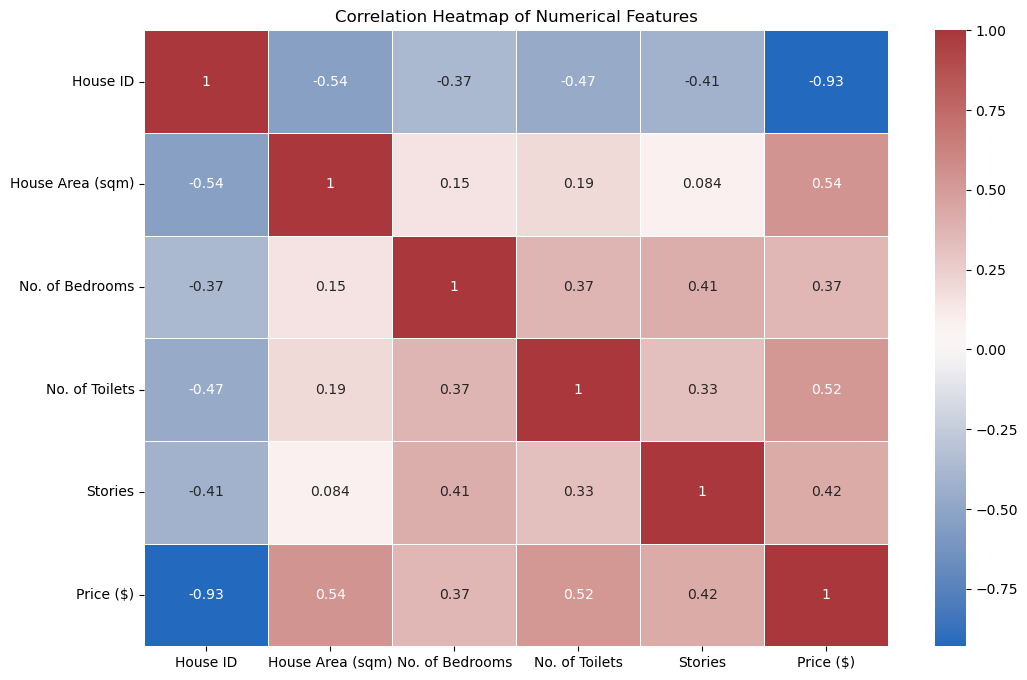

In [6]:
heatmap_cols = ['House ID', 'City', 'House Area (sqm)', 'No. of Bedrooms', 'No. of Toilets', 'Stories', 'Renovation Status', 'Price ($)']

# `.corr()` calculates how strongly each numeric feature relates to another
# `numeric_only=True` ensures non-numeric columns (like text) are ignored to avoid errors
corr_matrix = df[heatmap_cols].corr(numeric_only=True)


plt.figure(figsize=(12, 8))

# `annot=True` displays the correlation values directly inside the chart
# `linewidths=0.5` draws neat borders for easier visual separation between cells    
sns.heatmap(corr_matrix, annot=True, cmap='vlag', linewidths=0.5) #Temporary Color Combo

plt.title("Correlation Heatmap of Numerical Features")
plt.show()

## **Explanation of Heatmap (Correlation Matrix):**

A heatmap was generated to `visualise` the `correlation` between the housing features in the dataset.  

By doing so, it allows users to understand and analyse how strongly related each feature is to another.

It also allows users to know which feature has the highest correlation to the target variable: ***`'Price ($)`***'.  

### **Some Descriptions of the Correlation Heatmap Matrix:**
- Blue and Red colors indicate stronger negative and positive correlations respectively.  

- This visualisation provides insight into which features may be more important when predicting hosuing prices (Higher 'temperature').

- The heatmap displays which feature affects ***`'Price ($)'`*** the most.

From the heatmap, it is displayed that ***`'House Area (sqm)'`*** has the **`highest positive value`** of **`0.54`**, compared to other features.

- The positive value of **`0.54`** indicates that the housing area is directly proportional to the housing price at a rate of 0.54, i.e. if housing area increases, the housing prices increases at a rate of 0.54 times the housing area.



---
### **Double Checking For Missing Values:**
- Using the ***`'.isnull()'`*** function to detect for any missing values in our dataset.
- Adding ***`'.sum()'`*** to act as a counter to count how many cells have missing data.

In [7]:
print(df.isnull())
print(df.isnull().sum())

     House ID   City  House Area (sqm)  No. of Bedrooms  No. of Toilets  \
0       False  False             False            False           False   
1       False  False             False            False           False   
2       False  False             False            False           False   
3       False  False             False            False           False   
4       False  False             False            False           False   
..        ...    ...               ...              ...             ...   
540     False  False             False            False           False   
541     False  False             False            False           False   
542     False  False             False            False           False   
543     False  False             False            False           False   
544     False  False             False            False           False   

     Stories  Renovation Status  Price ($)  
0      False              False      False  
1      Fa

### **From the code above:**
- ***`'df.isnull()'`*** shows all columns with `'False'`, indicating that all columns are filled.
- To double check the presence of missing data, ***`'df.isnull().sum()'`*** is used, and it outputs `'0'` for all columns, also indicating that there is an absence of missing data.

--- 
## **Step 4:** Defining Feature Set and Preprocessing


- Text-based (object) columns are converted into numeric form using ***`'LabelEncoder()'`*** so that machine learning models can process them.

- Using **`df.drop()`** (Dropping Columns that are not needed/helpful in predicting Machine Status):


In [8]:
# LabelEncoder turns non-numeric labels into numbers so ML models can process them
le = LabelEncoder()

# Each column is transformed into numeric form using `fit_transform`
# This assigns a unique number to every category in that column
for col in df.select_dtypes(include=["object"]).columns:
    df[col] = le.fit_transform(df[col])


## **Step 4.5:** Feature Engineering - Addition of New Features

- New features to be added based on the features' relationships with each other from the correlation matrix heatmap

- The House ID column was dropped because they serve only as indentifiers and do not provide predictive value.

- Define **`df_model`** to contain the same set of features as **df** with the **`exclusion`** of **`'House ID'`** column.

In [9]:
# "House ID" is removed because it is a unique identifier and does not help the model learn useful patterns
df_model = df.drop("House ID", axis=1)

# Bedrooms per story helps compare houses fairly even if they have different numbers of floors
df_model['No. of Bedrooms Per Story'] = df_model['No. of Bedrooms'] / df_model['Stories']

# Toilets per story gives signal about how bathrooms are distributed in taller houses
df_model['No. of Toilets Per Story'] = df_model['No. of Toilets'] / df_model['Stories']

# Area per bedroom tells us if rooms are small or large relative to the house size
df_model['Area Per Bedroom'] =  df_model['House Area (sqm)'] / df_model['No. of Bedrooms'] 

# Toilets per bedroom signals whether bathroom count scales normally or abnormally with house size
df_model['Toilets Per Bedroom'] = df_model['No. of Toilets'] / df_model['No. of Bedrooms']

# Total rooms combines bedrooms + toilets to estimate overall house layout size
df_model['Total Rooms'] = df_model['No. of Bedrooms'] + df_model['No. of Toilets']

# Total rooms per area compares the house floorplan size relative to total living space
df_model['Total Rooms Per Area'] = df_model['Total Rooms'] / df_model['House Area (sqm)']

df_model

,City,House Area (sqm),No. of Bedrooms,No. of Toilets,Stories,Renovation Status,Price ($),No. of Bedrooms Per Story,No. of Toilets Per Story,Area Per Bedroom,Toilets Per Bedroom,Total Rooms,Total Rooms Per Area
0,1,742.0,4,2,3,0,1330000,1.333333,0.666667,185.500000,0.500000,6,0.008086
1,2,896.0,4,4,4,0,1225000,1.000000,1.000000,224.000000,1.000000,8,0.008929
2,1,996.0,3,2,2,1,1225000,1.500000,1.000000,332.000000,0.666667,5,0.005020
3,4,750.0,4,2,2,0,1221500,2.000000,1.000000,187.500000,0.500000,6,0.008000
4,3,742.0,4,1,2,0,1141000,2.000000,0.500000,185.500000,0.250000,5,0.006739
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,4,300.0,2,1,1,2,182000,2.000000,1.000000,150.000000,0.500000,3,0.010000
541,3,240.0,3,1,1,1,176715,3.000000,1.000000,80.000000,0.333333,4,0.016667
542,0,362.0,2,1,1,2,175000,2.000000,1.000000,181.000000,0.500000,3,0.008287
543,4,291.0,3,1,1,0,175000,3.000000,1.000000,97.000000,0.333333,4,0.013746


- Added 6 new features to implement:
    - Number of Bedrooms Per Story takes the average number of bedrooms per story (More bedrooms per floor - more expensive).
        - Similar for Number of Toilets Per Story
    - Area Per Bedroom, find the area of each bedroom in the house (Larger area for Bedroom - Bigger Bedroom - more expensive).
    - Toilets Per Bedroom finds the number of toilets per bedroom (More toilets in 1 bedroom - more expensive)
    - Total Rooms is the total number of toilets and bedrooms (More rooms, more expensive)
    - Total Rooms Per Area gives the number of existing rooms per square meter of the house - calculate room density
        - Check whether a house has more rooms packed into its area or fewer but larger rooms.

---

## **Step 5:** Defining The Datasets & Splitting Datasets Into Training and Testing Using **`train_test_split`**
The **`feature set (X)`** and **`target variable (y)`** are defined — with X being equated to ***`df_model[features]`*** (Original features without 'House ID', and the added features), and y representing the Housing Price.

The House ID column is removed since it does not contribute to the prediction.

The dataset is split into 2 sets, a training set and a testing set.

The training set is used to train the models, while the testing set is used to assess how well the model was trained based on its predictions on unseen data.


In [10]:
# X: takes all columns except price (input features the model will learn from)
# y: the price column becomes the prediction target
X = df_model.drop('Price ($)', axis=1)
y = df_model["Price ($)"]

# 20% of the data is kept unseen to test how well the model performs on new examples
# random_state=42 ensures the same split happens every run (for fair comparison when tuning)
X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                                    test_size=0.2, 
                                                    random_state=42)

# Scaling helps regression models train faster and treat all inputs fairly on the same scale
scaler = StandardScaler() 
                        
# `fit_transform` → learns mean and std from training, then applies scaling
# `transform` → applies the learned scaling to test data without re-learning (avoids data leakage)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


- From the code, the dataset is split into 80% training data and 20% testing data, storing it in X_train, y_train and X_test, y_test respectively.
    - This ensures that most of the data is used to train the model, while a smaller portion is reserved to evaluate its performance on unseen data.

- ***`random_state`*** was used as it is crucial for ensuring reproducibility in processes that involve randomness and it is set to 42.

- ***`random_state`*** is also a seed for the random number generator, allowing consistent and repeatable results across multiple runs.


- Why Training and test data for the feature set are scaled:
    - So that the model can learn fairly from every feature (Where big numbers might overpower the smaller ones).
        - Model might assume larger numbers hold a higher significance over smaller numbers as the model doesn't know which numbers are important, it just sees the size of them as it is trying to check how each feature affects the results while being trained.
    - Ensures it uses the same measurement system on the testing data the model trained from.
    - For Ridge and Lasso, it helps the regularization part work porperly as it penalizes features based on weights.
    - Makes features a similar size for proper training.

--- 
## **Step 6:** Instantiating & Fitting Training Data

In this step, mulitple models are instantiated and trained using the prepared training dataset.
- The model learns the patterns between the features and the target label, 'Prices ($)', for each sample.




### **RandomForestRegressor:**

In [11]:
# n_estimators=100 means the model uses 100 decision trees to make averaged regression outputs
# random_state=42 ensures consistent results when rerunning for testing or tuning
rfr = RandomForestRegressor(n_estimators=100, random_state=42)

# The model learns relationships between X (like rooms, area, floors, torque, etc.) and y (price)
rfr.fit(X_train_scaled, y_train)

# These predictions are stored as continuous numeric values for evaluation (MSE, RMSE, etc.)
rfr_pred = rfr.predict(X_test_scaled)

### **DecisionTreeRegressor:**

In [12]:
# max_depth=5 limits the tree to 5 levels to prevent overly complex rules and reduce overfitting
d_tree = DecisionTreeRegressor(max_depth=5)

# The model builds decision rules from X_train_scaled to learn how features relate to price 
d_tree.fit(X_train_scaled, y_train)

# Stored as continuous numeric outputs for comparison with other regression models later
d_tree_pred = d_tree.predict(X_test_scaled)

### **Ridge:**

In [13]:
# Ridge is a regression algorithm that learns patterns from features
# and reduces extreme weight values by applying a penalty (regularization)
# alpha=1.0 controls how strong that penalty is
ridge = Ridge(alpha=1.0)

# The model learns how input features relate to price   
ridge.fit(X_train_scaled, y_train)

# These predicted price values are stored in `ridge_pred` for evaluation later
ridge_pred = ridge.predict(X_test_scaled)

### **Lasso:**

In [14]:
# Lasso is a regression method that learns feature-based patterns like Ridge,
# but it can also push less useful feature weights to 0 (feature selection effect)
# alpha=0.01 sets the strength of that penalty
lasso = Lasso(alpha=0.01)

# The model learns room/area/story influence on Price ($)
lasso.fit(X_train_scaled, y_train)

# Outputs continuous price predictions stored for evaluation (e.g., error metrics later)
lasso_pred = lasso.predict(X_test_scaled)

c:\Users\nedya\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.520e+10, tolerance: 1.344e+09
  model = cd_fast.enet_coordinate_descent(


- Instantiating each of the models:
    - RandomForestRegressor
    - DecisionTreeRegressor
    - Ridge
    - Lasso
- Storing them into separate variables respectively:
    - rfr
    - d_tree
    - ridge
    - lasso
- ***`'.fit()'`*** function allows the imported model to be fitted to the scaled training data.
- Predictions are made on the test dataset using ***`'.pred()'`*** function to evaluate how accurately the model can classify unseen data.




- **`'RandomForestRegressor'`** uses a parameter of ***`'n_estimators'`***, similar to its classification counterpart, and its value is set to **`100`** as it is the standard number and it is a good starting parameter value to capture patterns without overfitting before tuning it.
- **`'DecistionTreeRegressor'`** uses a parameter of ***`'max_depth'`*** which is set to **`5`**, which sets the max number of splits that the tree can grow to to 5, to **`prevent overfitting`** of the data, and at the same time prevent the tree from being too simple to **`reduce underfitting`**.
- **`'Ridge'`** uses the parameter ***`'alpha'`*** which is set to **`1`**, which is the default regularization strength of the model.
- Similar to Ridge, **`'Lasso'`** also uses ***`'alpha'`*** but this time, its value is set to **`0.01`** as Lasso is more sensitive to alpha than Ridge, setting a value of 1 or higher might wipe out some values in the dataset.

--- 
## **Model Evaluations:**

The models are evaluated using: 
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- Mean Absolute Error (MAE)
- r2 Score
- Predicted vs Actual Graph
- Residual Plot (Show Error Patterns)

These help evaluate how well the model can predict housing prices based on past data.

---
## **Models' MSE:**

- Displays each model's mean squared error.



### **RandomForestRegressor:**

In [15]:
# MSE measures the average of the squared differences between predicted and actual prices
print("RandomForestRegressor's MSE:", mean_squared_error(y_test, rfr_pred))

RandomForestRegressor's MSE: 25492668112.922974


### **DecisionTreeRegressor:**

In [16]:
# MSE measures the average of the squared differences between predicted and actual prices
print("DecisionTreeRegressor's MSE:", mean_squared_error(y_test, d_tree_pred))

DecisionTreeRegressor's MSE: 27487136165.14635


### **Ridge:**

In [17]:
# MSE measures the average of the squared differences between predicted and actual prices
print("Ridge's MSE:", mean_squared_error(y_test, ridge_pred))

Ridge's MSE: 23821779368.341408


### **Lasso:**

In [18]:
# MSE measures the average of the squared differences between predicted and actual prices
print("Lasso's MSE:", mean_squared_error(y_test, lasso_pred))

Lasso's MSE: 23846627121.366745


- These show the mean squared errors of each model.
- Why **`MSE`**:
    - Takes the mean of the residual sum of squares
        - Shows the average squared difference between the predicted (model's predicted values in the form of a line graph) and actual values .
    - Shows which model has the smallest average squared difference between data and fit, showing which models' fit is the closest to the data.
    - Squared units of the target variable, price, thus measured in $^2.
    - A lower MSE indicates a more accurate model with lesser errors.
    - Penalizes larger errors more heaviy due to the effect of squaring the error (Highly Sensitive to outliers - further from graph, larger value).


---
## **Models' MAE:**
- Display each models mean absolute error.

### **RandomForestRegressor:**

In [19]:
# MAE measures the average size of the mistakes in the price predictions (not squared like MSE)
print("RandomForestRegressor's MAE:", mean_absolute_error(y_test, rfr_pred))

RandomForestRegressor's MAE: 116441.35013761469


### **DecisionTreeRegressor:**

In [20]:
# MAE measures the average size of the mistakes in the price predictions (not squared like MSE)
print("DecisionTreeRegressor's MAE:", mean_absolute_error(y_test, d_tree_pred))

DecisionTreeRegressor's MAE: 123735.92280581329


### **Ridge:**

In [21]:
# MAE measures the average size of the mistakes in the price predictions (not squared like MSE)
print("Ridge's MAE:", mean_absolute_error(y_test, ridge_pred))

Ridge's MAE: 113517.3840125503


### **Lasso:**

In [22]:
# MAE measures the average size of the mistakes in the price predictions (not squared like MSE)
print("Lasso's MAE:", mean_absolute_error(y_test, lasso_pred))

Lasso's MAE: 113472.8107444808


- Why MAE:
    - Mean Abosolute error takes the average absolute difference between predicted and actual value, however unlike MSE & RMSE, it takes the absolute value of the differences.
        - Doesn't take into account the effect of the positive and negative residual cancelling each other out due to the absolute.
    - Weighs all error equally since there is no squaring that gives more weight/emphasis on larger resiudals.
    - Bigger the MAE, less accurate the model is and vice versa.

---
## **Model's RMSE:**
- Display each models root mean squared error.

### **RandomForestRegressor:**

In [23]:
# RMSE takes the square root of MSE so the error is in normal price units ($)
print("RandomForestRegressor's RMSE:", np.sqrt(mean_squared_error(y_test, rfr_pred)))

RandomForestRegressor's RMSE: 159664.23554736035


### **DecisionTreeRegressor:**

In [24]:
# RMSE takes the square root of MSE so the error is in normal price units ($)
print("DecisionTreeRegressor's RMSE:", np.sqrt(mean_squared_error(y_test, d_tree_pred)))

DecisionTreeRegressor's RMSE: 165792.44905949835


### **Ridge:**

In [25]:
# RMSE takes the square root of MSE so the error is in normal price units ($)
print("Ridge's RMSE:", np.sqrt(mean_squared_error(y_test, ridge_pred)))


Ridge's RMSE: 154343.0574024676


### **Lasso:**

In [26]:
# RMSE takes the square root of MSE so the error is in normal price units ($)
print("Lasso's RMSE:", np.sqrt(mean_squared_error(y_test, lasso_pred)))


Lasso's RMSE: 154423.53163092321


- Why RMSE:
    - Takes the root of the MSE for easier understanding since it is following the units of target variable, price, hence it is $, instead of dollars squared like MSE.
        - easier to interpret
    - Functions the same as MSE, just in the same units as target variable, measures the average difference between the predicted and actual values.
    - Lower RMSE, better fit.

---
## **Models' R2 Score:**
- Display each model's R-squared score.

### **RandomForestRegressor:**

In [27]:
# R² measures how well the model explains the variation in price
# Score ranges from 0 to 1 (sometimes negative if model performs badly)
# Higher R² means better fit to the data
print("RandomForestRegressor's R-Squared Score:", r2_score(y_test, rfr_pred))

# converting to % for easier reading & analysis
print("For better visualization, RandomForestRegressor's R-Squared Score in Percentage:", r2_score(y_test, rfr_pred) * 100, "%")

RandomForestRegressor's R-Squared Score: 0.49565112620043983
For better visualization, RandomForestRegressor's R-Squared Score in Percentage: 49.56511262004398 %


### **DecisionTreeRegressor:**

In [28]:
# R² measures how well the model explains the variation in price
# Score ranges from 0 to 1 (sometimes negative if model performs badly)
# Higher R² means better fit to the data
print("DecisionTreeRegressor's R-Squared Score:", r2_score(y_test, d_tree_pred))

# converting to % for easier reading & analysis
print("For better visualization, DecisionTreeRegressor's R-Squared Score in Percentage:", r2_score(y_test, d_tree_pred) * 100, "%")

DecisionTreeRegressor's R-Squared Score: 0.4561924194259167
For better visualization, DecisionTreeRegressor's R-Squared Score in Percentage: 45.61924194259167 %


### **Ridge:**

In [29]:
# R² measures how well the model explains the variation in price
# Score ranges from 0 to 1 (sometimes negative if model performs badly)
# Higher R² means better fit to the data
print("Ridge's R-Squared Score:", r2_score(y_test, ridge_pred))

# converting to % for easier reading & analysis
print("For better visualization, Ridge's R-Squared Score in Percentage:", r2_score(y_test, ridge_pred) * 100, "%")

Ridge's R-Squared Score: 0.528708115482267
For better visualization, Ridge's R-Squared Score in Percentage: 52.870811548226705 %


### **Lasso:**

In [30]:
# R² measures how well the model explains the variation in price
# Score ranges from 0 to 1 (sometimes negative if model performs badly)
# Higher R² means better fit to the data
print("Lasso's R-Squared Score:", r2_score(y_test, lasso_pred))

# converting to % for easier reading & analysis
print("For better visualization, Lasso's R-Squared Score in Percentage:", r2_score(y_test, lasso_pred) * 100, "%")

Lasso's R-Squared Score: 0.5282165256573312
For better visualization, Lasso's R-Squared Score in Percentage: 52.821652565733125 %


- Why R2 Score:
    - also known as the coefficient of determination and serves as a goodness-of-fit measure.
    - In simpler terms, it measures how well the observed data fit the regression model's predictions.
        - Example: Ridge has an R2 Score of 52.87%, meaning that 52.87% of the variability observed in the dependent variable (Price) is explained by the independent variables (Features)


## **Summary of Each Model's Evaluation (Based on MSE, RMSE, MAE * R2 Score):**
- **MSE:**
    - **`DecisionTreeRegressor`** had the **`highest`** Mean Squared Error of the 4 Models.
        - **$^2  28920273779.83 (2 d.p) (Dollars Squared)**.
    - **`Ridge`** had the **`lowest`** Mean Squared Error of the 4.
        - **$^2 23821779368.34 (2 d.p) (Dollars Squared)**.

- **MAE:**
    - **`DecisionTreeRegressor`** had the **`highest`** Mean Absolute Error of the 4.
        - **$125020.33 (2 d.p)**
    - **`Lasso`** had the **`lowest`** Mean Absolute Error of the 4, with **`Ridge`** **not** that **`far behind`**.
        - **$113472.81 (2 d.p) for Lasso and $113517.38 (2 d.p) for Lasso.**
        - Difference is rather minimal.

- **RMSE:**
    - **`DecisionTreeRegressor`** had the **`highest`** Root Mean Squared Error of the 4 models.
        - **$170059.62 (2 d.p)**
    - **`Ridge`** had the **`lowest`** Root Mean Squared Error of the 4 models, although **`Lasso`** is **`not so far behind`** Ridge.
        - **$154423.53 (2 d.p) for Lasso and $154343.056 (2 d.p) for Ridge.**
        - Difference is relatively small.

- **R-Squared Score:**
    - **`Lasso`** and **`Ridge`** have the **`2 highest R2 Score`** of the 4 models, with **`Ridge`** having a **`slightly higher`** score than Lasso.
        - **0.5282165256573312 (52.82% (2 d.p)) for Lasso and 0.528708115482267 (52.87% (2 d.p)) for Ridge.**
    - **RandomForestRegressor** had an R2 Score of  **0.49565112620043983** **(49.57% (2 d.p))**.
    - **DecisionTreeRegressor** had the lowest R2 Score of **0.4121100469040756** **(41.21% (2 d.p))**.



## **Conclusion:**
- Since Ridge and Lasso produced the strongest evaluation metrics among all four regression models tested, the comparison will focus only on these two models, while the other 2 will be dropped.

--- 
## **Model Evaluations Part 2:**

### **Comparison Between Ridge and Lasso via Bar Graph:**

- Since the metrics of Ridge and Lasso differ only by a small margin, a bar graph will be plotted to better visualise their differences and hence make for easier comparison and evaluation.

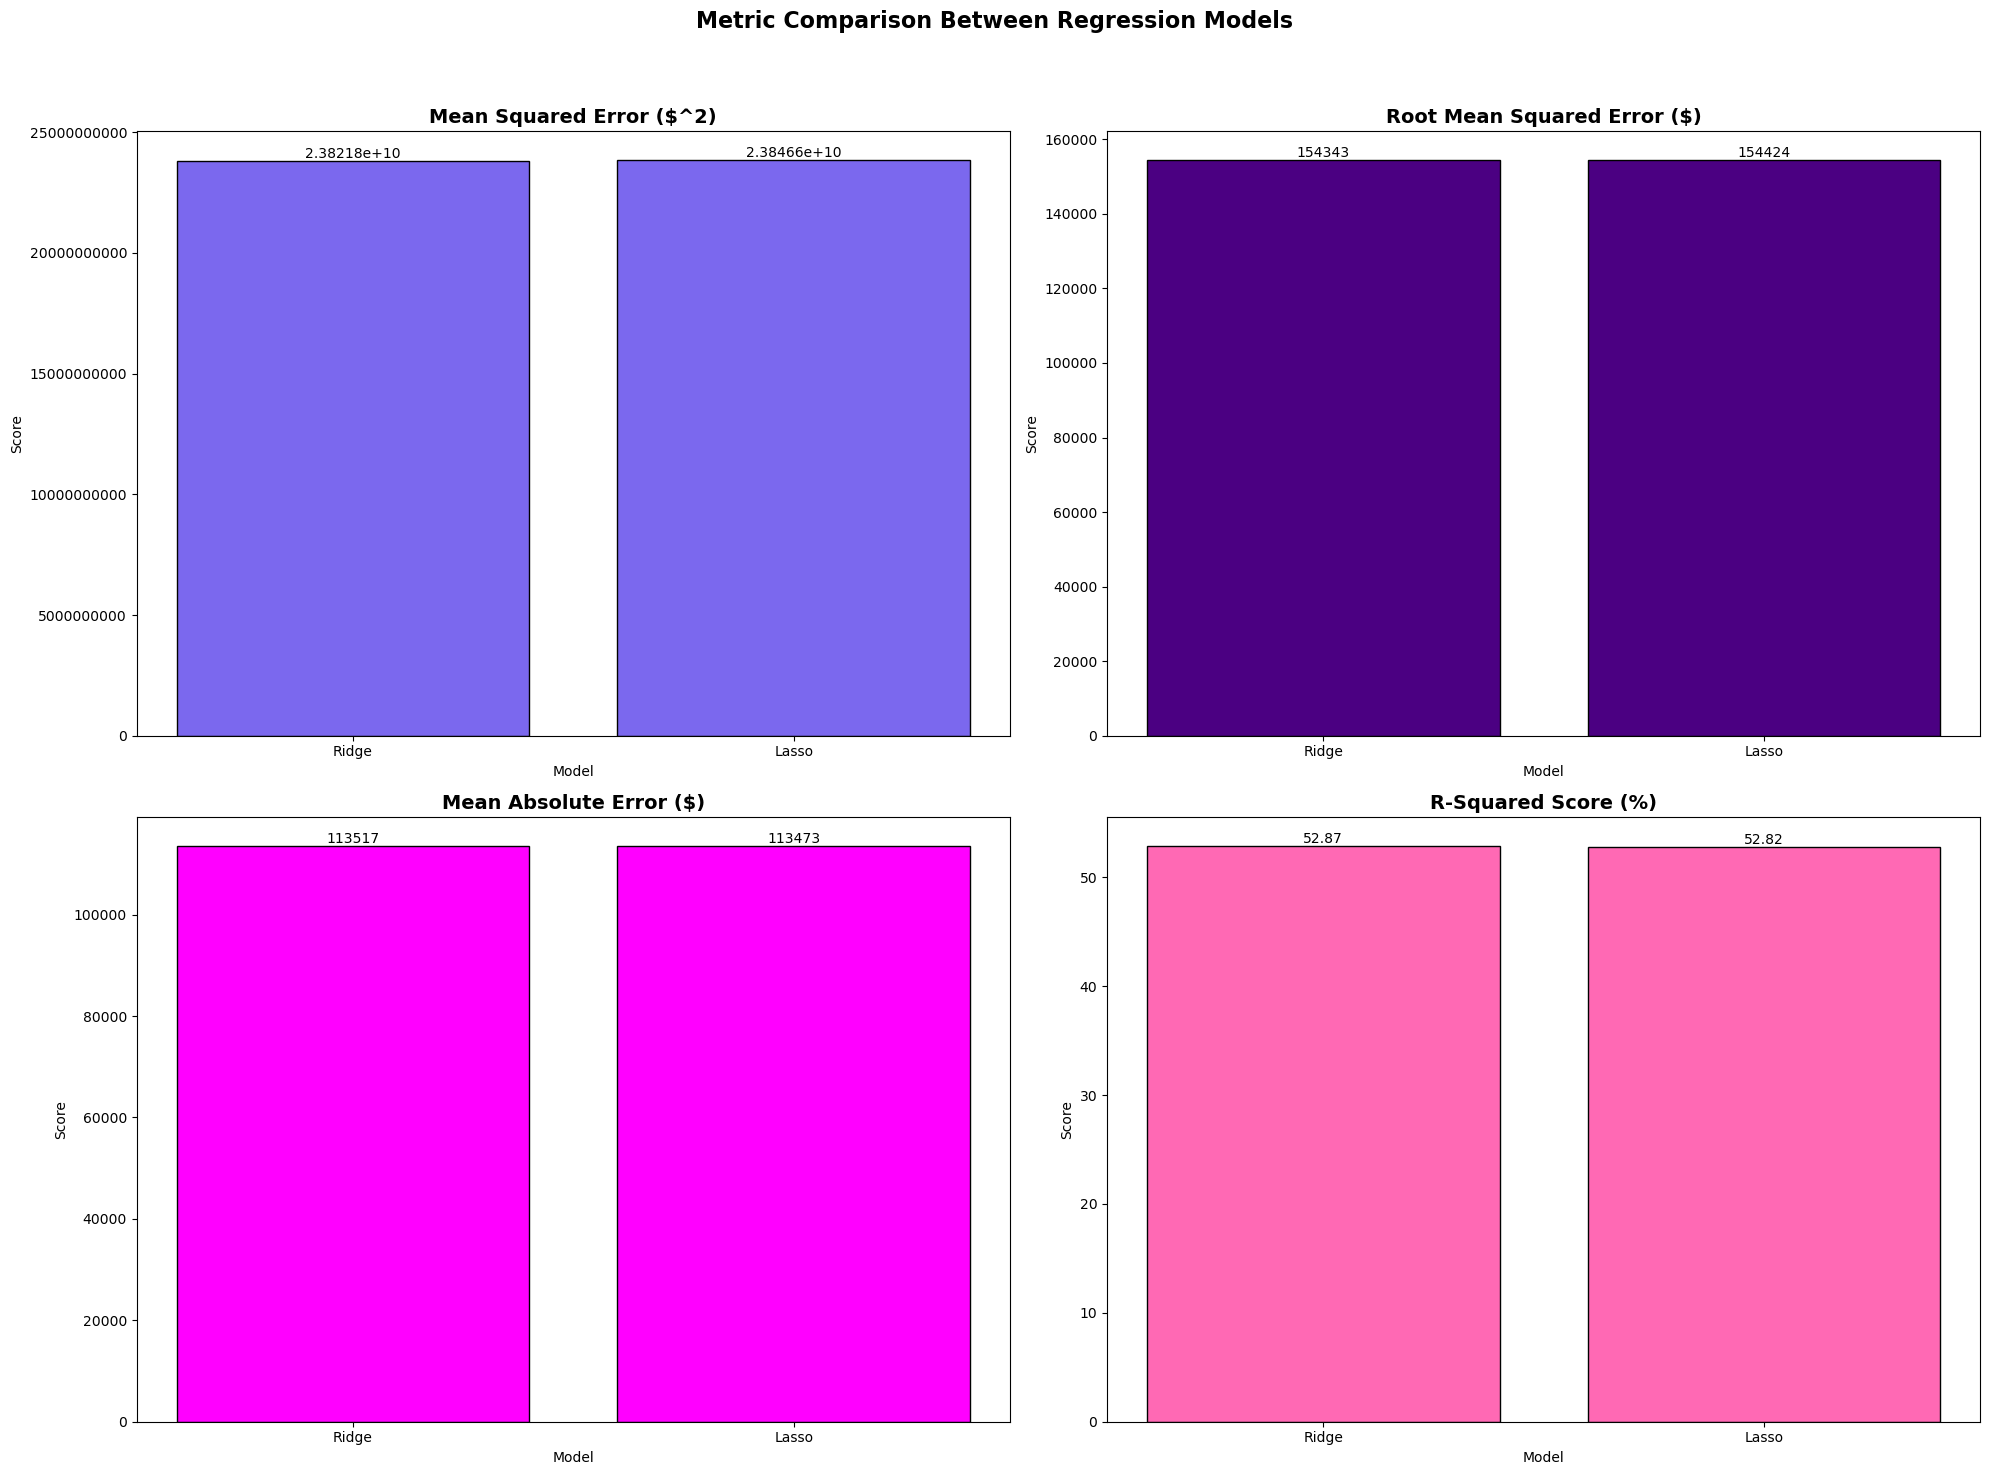

In [31]:
 # names of the regression models being compared for visualization labels
models = ['Ridge', 'Lasso']

# Collect all metrics in ONE simple dictionary
# Each metric stores a list: [Ridge_score, Lasso_score] for direct comparison
metrics = {
    "Mean Squared Error ($^2)": [
        round(mean_squared_error(y_test, ridge_pred), 2),
        round(mean_squared_error(y_test, lasso_pred), 2)
    ],
    "Root Mean Squared Error ($)": [
        round(np.sqrt(mean_squared_error(y_test, ridge_pred)), 2),
        round(np.sqrt(mean_squared_error(y_test, lasso_pred)), 2)
    ],
    "Mean Absolute Error ($)": [
        round(mean_absolute_error(y_test, ridge_pred), 2),
        round(mean_absolute_error(y_test, lasso_pred), 2)
    ],
    "R-Squared Score (%)": [
        round(r2_score(y_test, ridge_pred) * 100, 2),
        round(r2_score(y_test, lasso_pred) * 100, 2)
    ]
}

colors = ['mediumslateblue', 'indigo', 'magenta', 'hotpink']

# Flatten ensures easier looping without nested indexing
fig, axs = plt.subplots(2, 2, figsize=(20, 15))
axs = axs.flatten()

fig.suptitle("Metric Comparison Between Regression Models", fontsize=16, fontweight='bold')

# Loop and create each plot
# Each subplot visualizes a different evaluation score array
for i, (metric_name, values) in enumerate(metrics.items()):
    ax = axs[i]

    # Bar plot: x-axis = model names, y-axis = their metric values
    bars = ax.bar(models, values, color=colors[i], edgecolor='black')
    
    # Displays numeric metric values on top of bars for quick interpretation
    ax.bar_label(bars, fontsize=10)

    ax.set_title(metric_name, fontsize=14, fontweight='bold')
    ax.set_xlabel("Model") # shows which algorithm the score belongs to
    ax.set_ylabel("Score") # metric output scale in the chosen unit
    ax.ticklabel_format(style='plain', axis='y')   # remove scientifci notation

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


### **Key Insights from Bar Charts:**

- The difference across the 4 evaluated metrics is very small, meaning both models perform almost similarly in this test.

- Ridge Regression scored slightly higher in:
    - Mean Absolute Error (MAE), showing a marginally better average prediction difference
    - R-Squared Score, explaining the variance slightly better than Lasso

- Lasso Regression scored slightly higher in:
    - Mean Squared Error (MSE)
    - Root Mean Squared Error (RMSE), meaning it had slightly lower large error impact

- Overall, neither model shows a major advantage — both are reasonable but nearly equal options based on this comparison.

## **Another Visualization (Addition of Cross Validation):**

c:\Users\nedya\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.781e+10, tolerance: 1.185e+09
  model = cd_fast.enet_coordinate_descent(
c:\Users\nedya\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.877e+10, tolerance: 1.089e+09
  model = cd_fast.enet_coordinate_descent(
c:\Users\nedya\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.278e+11, toleranc

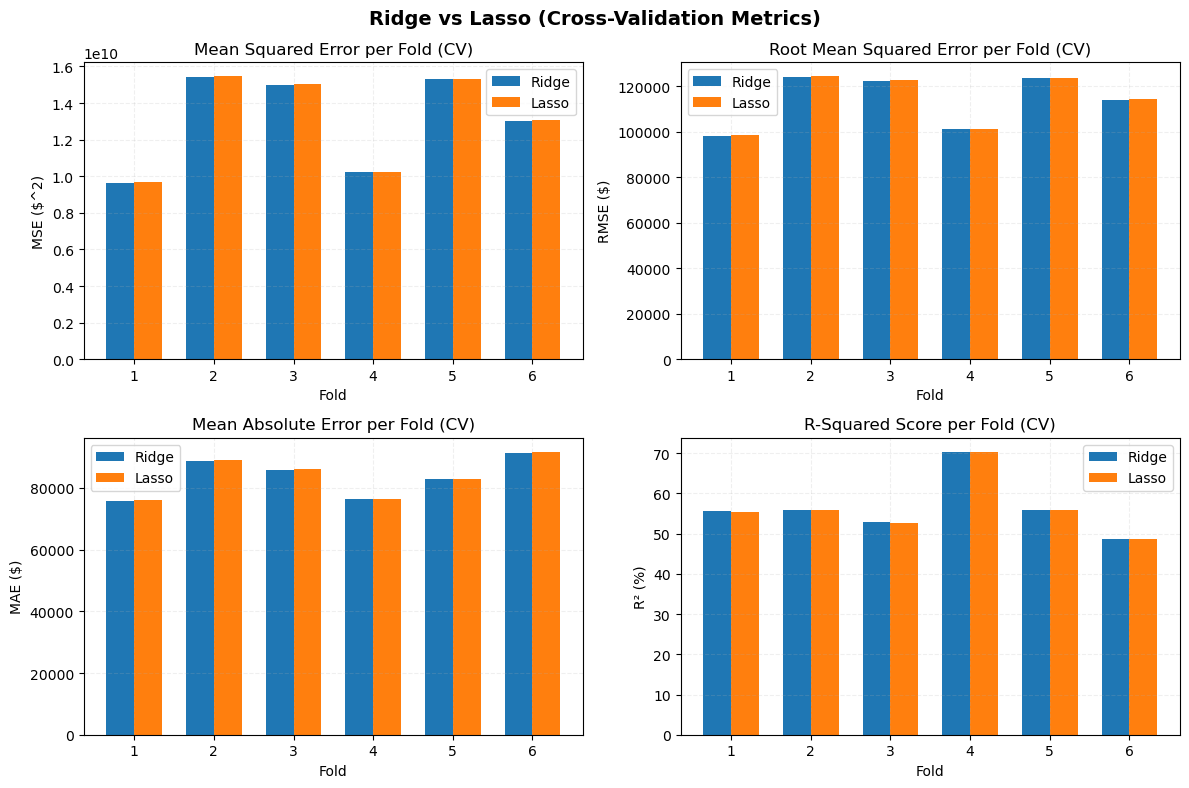

In [32]:
# names of the regression models being compared for visualization labels
models   = ['Ridge', 'Lasso']


# 6 folds means the dataset is split into 6 different train/test combinations to measure stability
# Shuffle prevents ordered grouping bias, random_state keeps the splits reproducible
kf = KFold(n_splits=6, random_state=42, shuffle=True)

# Now compute 4 real CV metrics
# R² shows how well the model fits each fold’s data (higher = better fit)
ridge_cv_r2 = cross_val_score(ridge, X_train_scaled, y_train, cv=kf, scoring='r2')
lasso_cv_r2 = cross_val_score(lasso, X_train_scaled, y_train, cv=kf, scoring='r2')

# neg_mean_squared_error and neg_mean_absolute_error are negated so the optimizer can treat lower = better
ridge_cv_mse = cross_val_score(ridge, X_train_scaled, y_train, cv=kf, scoring='neg_mean_squared_error')
lasso_cv_mse = cross_val_score(lasso, X_train_scaled, y_train, cv=kf, scoring='neg_mean_squared_error')

ridge_cv_mae = cross_val_score(ridge, X_train_scaled, y_train, cv=kf, scoring='neg_mean_absolute_error')
lasso_cv_mae = cross_val_score(lasso, X_train_scaled, y_train, cv=kf, scoring='neg_mean_absolute_error')

# Convert negative scores back to positive error values
# This restores the error magnitude into interpretable price units
ridge_mse_scores = [round(abs(x), 2) for x in ridge_cv_mse]
lasso_mse_scores = [round(abs(x), 2) for x in lasso_cv_mse]

ridge_mae_scores = [round(abs(x), 2) for x in ridge_cv_mae]
lasso_mae_scores = [round(abs(x), 2) for x in lasso_cv_mae]

# RMSE is sqrt of MSE per fold
# RMSE is easier to explain because it is now in the same unit as price ($)
ridge_rmse_scores = [round(np.sqrt(x), 2) for x in ridge_mse_scores]
lasso_rmse_scores = [round(np.sqrt(x), 2) for x in lasso_mse_scores]

# Percentage form is clearer when presenting results
ridge_r2_scores = [round(x * 100, 2) for x in ridge_cv_r2]
lasso_r2_scores = [round(x * 100, 2) for x in lasso_cv_r2]

folds = range(1, 7) # Fold numbers for x-axis labels
x = np.arange(len(folds)) # Positions on x-axis for the bars

bar_width = 0.35

# 4 subplot titles and your 4 metrics (6 folds × 2 models)
# Each tuple contains: chart title, ridge values, lasso values, y-axis label
metrics = [
    ("Mean Squared Error per Fold (CV)", ridge_mse_scores, lasso_mse_scores, "MSE ($^2)"),
    ("Root Mean Squared Error per Fold (CV)", ridge_rmse_scores, lasso_rmse_scores, "RMSE ($)"),
    ("Mean Absolute Error per Fold (CV)", ridge_mae_scores, lasso_mae_scores, "MAE ($)"),
    ("R-Squared Score per Fold (CV)", ridge_r2_scores, lasso_r2_scores, "R² (%)")
]

plt.figure(figsize=(12, 8))
plt.suptitle("Ridge vs Lasso (Cross-Validation Metrics)", fontsize=14, fontweight='bold')

# Each subplot overlays ridge and lasso to compare how both models perform per fold
for i, (title, ridge_vals, lasso_vals, ylabel) in enumerate(metrics, 1):
    plt.subplot(2, 2, i)

    # Ridge and Lasso bars are plotted side-by-side at each fold position
    plt.bar(x, ridge_vals, width=bar_width, label='Ridge')
    plt.bar(x + bar_width, lasso_vals, width=bar_width, label='Lasso')

    # Subplot is decorated with labels and grid for insight clarity
    plt.title(title) # Metric chart title
    plt.xlabel("Fold") # Indicates which fold test the bar result belongs to
    plt.ylabel(ylabel) # Shows the correct metric scale/unit
    plt.xticks(x + bar_width/2, folds) # Center x-ticks under bar pairs
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.2) # Light grid for easier value tracking
 
plt.tight_layout()
plt.show()


- Here is also another visual example where:
    - Ridge has a higher MSE and RMSE than Lasso
    - Lasso has a higher MAE and R-Squared Score
    Ridge and Lasso both perform closely across most folds

- Ridge tends to be slightly more stable (less variation)

- Fold 4 has the highest R2 score for both models → best general pattern learning

- Fold 2, 5, 6 show higher MSE/RMSE/MAE
    - showing that models struggled more on these splits

- Lasso often has a lower or equal error than Ridge on some folds, meaning removed features may be helping at times


---
## **Hyperparameter Tuning:**

- Looking at the 2 visuals, Ridge may have a higher Mean Absolute Error than Lasso, but it has a lower value for Mean Squared Error and its root, whist having a higher R-Squared Score than Lasso.
- Thus, Ridge will be the model that'll have its parameters tuned to give the best achieveable outcomes. 

### **Tuning Ridge:**

In [33]:
# alpha controls regularization strength, solvers are optimization methods,
# tol and max_iter affect training convergence, intercept toggles bias term inclusion
param_grid = {
    'alpha': [0.001, 0.01, 0.1,0.5, 1, 2, 5, 10],
    # 'solver': ['auto', 'lsqr', 'sag', 'saga'],
    'tol': [0.0001, 0.0005, 0.001, 0.01],
    'max_iter': [1000, 3000, 5000],
    'fit_intercept': [True, False]
}

# Set up GridSearchCV: 
# Uses 5-fold CV to test parameter combinations on multiple splits
# scoring='r2' evaluates fit quality per combination (higher is better)
# n_jobs=-1 runs search using all CPU cores for faster processing
# verbose=2 prints progress updates while training combinations
grid_search = GridSearchCV(
    estimator=ridge,
    param_grid=param_grid,
    cv=5,                  # 5-fold cross validation
    scoring='r2',          # scoring metric (you can use accuracy/recall/f1)
    n_jobs=-1,             # use all processor cores
    verbose=2              # show progress
)

# Run the grid search
# This step evaluates every config and ranks them by R² performance
grid_search.fit(X_train_scaled, y_train)

# Best hyperparameters
# Useful for documenting selected settings in your report or explaining tuning results
print("Best Hyperparameters:", grid_search.best_params_)

#  Best model from grid search
# `.best_estimator_` outputs the model instance trained using the top-ranked params
best_ridge_params = grid_search.best_estimator_

#  Evaluate on test set
# This evaluates real model generalization since test data was not part of tuning
best_pred = best_ridge_params.predict(X_test_scaled)


print('MSE:', mean_squared_error(y_test, best_pred))
print('\nRMSE:', np.sqrt(mean_squared_error(y_test, best_pred)))
print('\nMAE:', mean_absolute_error(y_test, best_pred))
print('\nR-Squared Score:', r2_score(y_test, best_pred) * 100)

Fitting 5 folds for each of 192 candidates, totalling 960 fits
Best Hyperparameters: {'alpha': 2, 'fit_intercept': True, 'max_iter': 1000, 'tol': 0.0001}
MSE: 23803944280.81332

RMSE: 154285.26916336932

MAE: 113552.18836428843

R-Squared Score: 52.90609662026806


### **Results from GridSearch:**


From the Results of ***`GridSearchCV`***, the best parameters to use for Random Forest are:
- **`alpha: 2`**
- **`'fit_intercept' : True`**
- **`'max_iter : 1000`** 
- **`'tol: 0.0001`**

The output above evaluates the performance of the **`Ridge`** model after implementing the newly tuned hyperparameter combination into Ridge.  
The 4 key metrics, **`MSE`**, **`RMSE`**, **`MAE`** & **`R2 Score`** are used to measure how well the model performs at predicting housing prices.

- **MSE** decreased from 23821779368.34 to 23803944280.81 in dollars squared.
- **RMSE** decreased from $154343.06 to $154285.27.
- **MAE** increased from $113517.38 to $113552.19.
- **R2 Score** increased from 52.87% to 52.91%.

Hence, this newly tuned model provides better overall results despite the slight increase in Mean Absolute Error.



--- 
## **Evaluation 2 - Comparision with Dummy Model**
- Instantiating and fitting a dummy model to be used as a control test to compare the tuned model with.

### **Equating DummyRegressor into Variable, Instantiate and Fit Model:**
-***`'DummyRegressor'`*** is stored into a variable called ***`'dummy'`***
- use ***`'.fit(X_train_scaled, y_train)'`*** to fit the scaled feature training data and the target training data
- use ***`'.predict(X_test_scaled)'`*** to predict the scaled test data for the feature set and storing it into the variable ***`'dummy_pred'`***.

In [34]:
# 'median' strategy means the model will always predict the median house price
# instead of learning patterns — useful to check if trained models improve over a constant rule
dummy = DummyRegressor(strategy='median')

# Although it doesn't learn relationships, it still needs y_train to compute the median value
dummy.fit(X_train_scaled, y_train)

# These predictions will act as a baseline when comparing real regression models later  
dummy_pred = dummy.predict(X_test_scaled)

- ***`'strategy'`*** is set to ***`'median'`***.
- Chose median as it does not take major outliers into account as median measures the middle position and returns the value at that position.
- Meaning that the dummy will just predict the median values for all housing prices.

### **Dummy's MSE:**

In [35]:
# This error tells us how far off the median-based predictions are compared to real prices.
# MSE acts as a reference point to judge whether real ML regression models are actually improving.
dummy_mse = round(mean_squared_error(y_test, dummy_pred), 2)
print("Dummy Model's Mean Squared Error: $^2", dummy_mse)

Dummy Model's Mean Squared Error: $^2 55679950848.62


### **Dummy's RMSE:**

In [36]:
# RMSE makes it easier to explain how far off the dummy model is on average.
dummy_rmse = round(np.sqrt(dummy_mse), 2)
print("Dummy Model's Root Mean Squared Error: $", dummy_rmse)

Dummy Model's Root Mean Squared Error: $ 235966.0


### **Dummy's MAE:**

In [37]:
# MAE measures the average difference between the median price predictions and the real test prices.
# Unlike MSE, this is not squared, so the result is directly interpretable in dollars ($).
dummy_mae = round(mean_absolute_error(y_test, dummy_pred), 2)
print("Dummy Model's Mean Absolute Error: $", dummy_mae)

Dummy Model's Mean Absolute Error: $ 176390.37


### **Dummy's R2 Score:**

In [38]:
# Since this model always predicts the median, R² is expected to be low.
# Multiplying by 100 converts it into a percentage, which is more intuitive for presentation.
dummy_r2 = round((r2_score(y_test, dummy_pred)) * 100, 2)
print("Dummy Model's R-Squared Score in %: ", dummy_r2, '%')

Dummy Model's R-Squared Score in %:  -10.16 %


---
## **Summary of Dummy's Metrics:**

- **`MSE:`**
    - Dummy has a very high MSE of **`$^255679950848.62 (2 d.p)`** in dollars squared.

- **`RMSE:`**
    - Dummy has a RMSE of **`$235966`**.

- **`MAE:`**
    - Dummy has a MAE of **`$176390.37 (2 d.p)`**.

- **`R2 Score:`**
    - Dummy has a R2 score of **`-10.16% (2 d.p)`**.
    - Dummy performs slightly worse than just predicting a constant perfectly.
    - Shows that it **`can't capture any trend`**. 


---
## **Comparison of Metrics Between Dummy Model and Lasso Model:**

- Compare the metrics of the dummy model with the Lasso model to see how they differ from each other.
- Comparison via visuals.

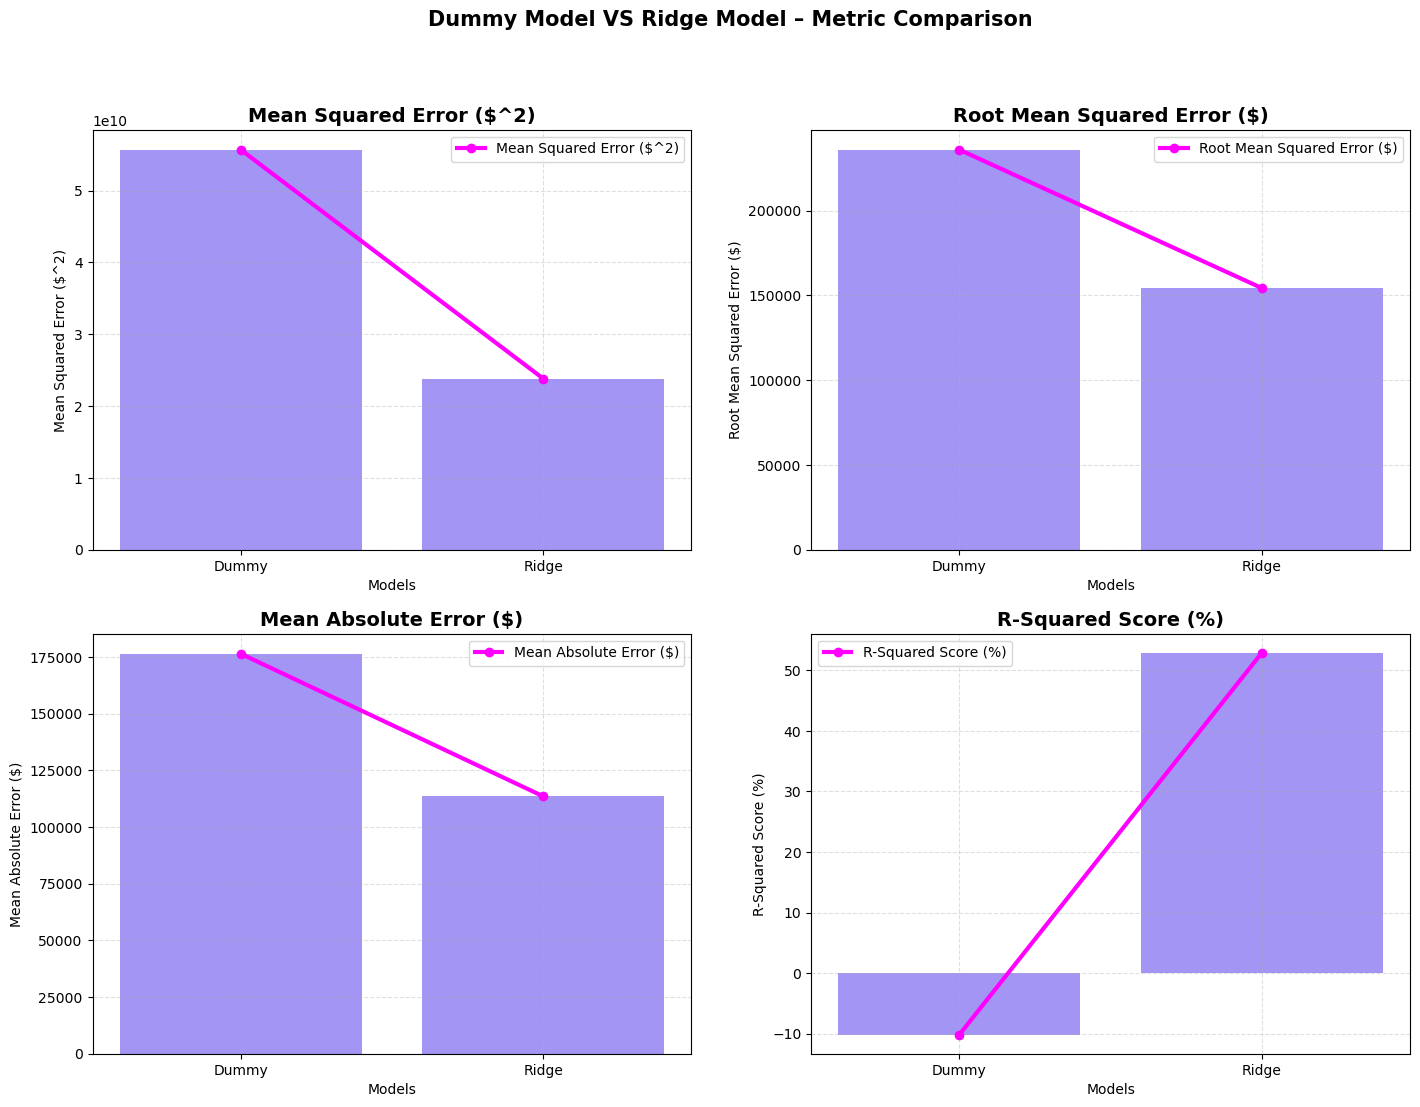

In [39]:

# These metrics measure prediction error (MSE, RMSE, MAE) and model fit quality (R²)
# Results are rounded for cleaner reporting or display
ridge_mse = round(mean_squared_error(y_test, ridge_pred), 2)
ridge_rmse = round(np.sqrt(mean_squared_error(y_test, ridge_pred)), 2)
ridge_mae = round(mean_absolute_error(y_test, ridge_pred), 2)
ridge_r2 = round((r2_score(y_test, ridge_pred) * 100), 2)


lasso_mse = round(mean_squared_error(y_test, lasso_pred), 2)
lasso_rmse = round(np.sqrt(mean_squared_error(y_test, lasso_pred)), 2)
lasso_mae = round(mean_absolute_error(y_test, lasso_pred), 2)
lasso_r2 = round((r2_score(y_test, lasso_pred) * 100), 2)

# Each index position matches the order in `metric_names` for direct comparison
ridge_metrics = [ridge_mse, ridge_rmse, ridge_mae, ridge_r2]
dummy_metrics = [dummy_mse, dummy_rmse, dummy_mae, dummy_r2]

# Helps viewers understand which error or fit measure is being visualized
metric_names = ['Mean Squared Error ($^2)', 'Root Mean Squared Error ($)', 'Mean Absolute Error ($)', 'R-Squared Score (%)']

# 17×12 ensures the line plots and bars are legible in reports or study materials
plt.figure(figsize=(17, 12))
plt.suptitle('Dummy Model VS Ridge Model – Metric Comparison', fontsize=15, fontweight='bold')

# Line shows trend (dummy vs learned model), bars show value magnitude
# Overlay helps emphasize how Ridge reduces baseline error and improves fit
for i, metric in enumerate(metric_names, 1):
    plt.subplot(2, 2, i)

    # Line plot overlays 2 values per metric: Dummy baseline vs Ridge tuned model
    # Helps highlight performance improvement from pattern learning + regularization
    plt.plot(['Dummy', 'Ridge'], [dummy_metrics[i-1], ridge_metrics[i-1]], marker='o', linewidth=3, label=metric, color='magenta')

    # Bar plot added per subplot to show metric magnitude side-by-side clearly
    # alpha for slight transparency to avoid visual heaviness on output
    plt.bar(['Dummy', 'Ridge'], [dummy_metrics[i-1], ridge_metrics[i-1]], alpha=0.7, color='mediumslateblue')

    plt.title(metric_names[i-1], fontsize=14, fontweight='bold')
    plt.ylabel(metric_names[i-1]) # Y-axis describes metric unit/meaning
    plt.xlabel('Models') # X-axis shows model names being compared
   
    # Grid helps make visual trend spotting easier across metric groups
    plt.grid(True, linestyle='--', alpha=0.4)

    # Legend identifies the overlay line + bar values as belonging to this metric
    plt.legend()

# Format y-axis labels to avoid scientific notation for easier student readability
plt.ticklabel_format(style='plain', axis='y')

# Display the graphs
plt.show()





### **Summary of Visual:**
- Conclusions Derived From Bar Chart:
    - Lasso has lower error metrics (MSE, RMSE, MAE) as compared to the Dummy model, showing prediction improvement.
    - The large error values of the Dummy model show that it is unable to predict the dataset precisely.
    - The model comparison confirms that constant baselines are not suitable for real deployment (real-world contexts).
    - The graph shows that Lasso predicts much more accurately than a constant baseline, proving it learned useful patterns from the input features.

---
## **Summary of Part B:**


- Implemented **`RandomForestRegressor`**, **`DecisionTreeRegressor`**, **`Ridge`** & **`Lasso`** regression models from scikit-learn.

- Evaluated the 4 models using **`MSE`**, **`RMSE`**, **`MAE`**, and **`R-Squared Score`** on test data.

- `Dropped` **`RandomForestRegressor`** and **`DecisionTreeRegressor`** due to poorer performance.

- `Compared` between **`Ridge`** & **`Lasso`** and displayed their metric results via bar chart and line chart.

- Decided to use **`Ridge over Lasso`** due to better performance, though the difference in scores is very little.

- Tuned Ridge's parameters using GridSearchCV, r2 score improved from 52.82% to 52.91% (2 d.p).

- Compared Ridge against a Dummy baseline to check if real learning occurred

- Observed Ridge produced much lower prediction errors than Dummy.

- Dummy R-Squared Score was negative, -10.16% (2 d.p) while Ridge's was 52.91% (2 d.p), displaying a clear performance gap.

- Plotted Bar Chart to visualise the comparison between Dummy & Ridge.

- Limited improvement from tuning suggests the dataset has high noise and the model may have reached its practical performance limit.